In [16]:
print("Bala Harshini B - 24BAD015")
import numpy as np
import pandas as pd
import time
import re
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout

Bala Harshini B - 24BAD015


In [2]:
from tensorflow.keras.datasets import imdb

vocab_size = 10000

(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=vocab_size)

print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples: 25000
Testing samples: 25000


In [3]:
word_index = imdb.get_word_index()

reverse_word_index = {value: key for key, value in word_index.items()}

def decode_review(sequence):
    return " ".join(
        reverse_word_index.get(i - 3, "?")
        for i in sequence
    )

texts = [decode_review(x) for x in x_train]

labels = np.array(y_train)

print(texts[0])
print("Label:", labels[0])

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
? this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert ? is an amazing actor and now the same being director ? father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for ? and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also ? to the two little boy's that played the ? of norman and paul they were just brilliant children are often left out of the ? list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should

In [4]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

texts = [clean_text(text) for text in texts]

print(texts[0])


this film was just brilliant casting location scenery story direction everyones really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also to the two little boys that played the of norman and paul they were just brilliant children are often left out of the list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should be praised for what they have done dont you think the whole stor

In [5]:
X_train, X_val, y_train, y_val = train_test_split(
    texts,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print("Training data:", len(X_train))
print("Validation data:", len(X_val))

Training data: 20000
Validation data: 5000


In [6]:
max_words = 10000
max_len = 200

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

print("Training shape:", X_train_pad.shape)
print("Validation shape:", X_val_pad.shape)

Training shape: (20000, 200)
Validation shape: (5000, 200)


In [7]:
def create_rnn_model():
    model = Sequential([
        Embedding(max_words, 128, input_length=max_len),
        SimpleRNN(64),
        Dropout(0.3),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [8]:
rnn_model = create_rnn_model()

start_time = time.time()

rnn_history = rnn_model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=5,
    batch_size=64,
    verbose=1
)

rnn_time = time.time() - start_time

rnn_predictions = (rnn_model.predict(X_val_pad) > 0.5).astype(int).flatten()

rnn_accuracy = accuracy_score(y_val, rnn_predictions)
rnn_precision = precision_score(y_val, rnn_predictions)
rnn_recall = recall_score(y_val, rnn_predictions)
rnn_f1 = f1_score(y_val, rnn_predictions)

print("RNN Training Time:", rnn_time)
print("Accuracy:", rnn_accuracy)
print("Precision:", rnn_precision)
print("Recall:", rnn_recall)
print("F1 Score:", rnn_f1)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 47s 130ms/step - accuracy: 0.5005 - loss: 0.7040 - val_accuracy: 0.5044 - val_loss: 0.6940
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 29s 93ms/step - accuracy: 0.5811 - loss: 0.6638 - val_accuracy: 0.5090 - val_loss: 0.7074
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 39s 88ms/step - accuracy: 0.6611 - loss: 0.5526 - val_accuracy: 0.5194 - val_loss: 0.7502
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 42s 90ms/step - accuracy: 0.7154 - loss: 0.4498 - val_accuracy: 0.5096 - val_loss: 0.8328
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 29s 92ms/step - accuracy: 0.7366 - loss: 0.4075 - val_accuracy: 0.5006 - val_loss: 0.9014
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step
RNN Training Time: 198.54104471206665
Accuracy: 0.5006
Precision: 0.5004585753592173
Recall: 0.6548
F1 Score: 0.5673193553976781


In [9]:
def create_lstm_model():
    model = Sequential([
        Embedding(max_words, 128, input_length=max_len),
        LSTM(64),
        Dropout(0.3),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [10]:
lstm_model = create_lstm_model()

start_time = time.time()

lstm_history = lstm_model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=5,
    batch_size=64,
    verbose=1
)

lstm_time = time.time() - start_time

lstm_predictions = (lstm_model.predict(X_val_pad) > 0.5).astype(int).flatten()

lstm_accuracy = accuracy_score(y_val, lstm_predictions)
lstm_precision = precision_score(y_val, lstm_predictions)
lstm_recall = recall_score(y_val, lstm_predictions)
lstm_f1 = f1_score(y_val, lstm_predictions)

print("LSTM Training Time:", lstm_time)
print("Accuracy:", lstm_accuracy)
print("Precision:", lstm_precision)
print("Recall:", lstm_recall)
print("F1 Score:", lstm_f1)

Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


313/313 ━━━━━━━━━━━━━━━━━━━━ 105s 329ms/step - accuracy: 0.5192 - loss: 0.6906 - val_accuracy: 0.5404 - val_loss: 0.6970
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 76s 243ms/step - accuracy: 0.5582 - loss: 0.6742 - val_accuracy: 0.5652 - val_loss: 0.6652
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 76s 243ms/step - accuracy: 0.6801 - loss: 0.5780 - val_accuracy: 0.7640 - val_loss: 0.5454
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 244ms/step - accuracy: 0.7686 - loss: 0.5134 - val_accuracy: 0.7888 - val_loss: 0.5156
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 78s 249ms/step - accuracy: 0.7815 - loss: 0.4858 - val_accuracy: 0.7872 - val_loss: 0.5142
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step
LSTM Training Time: 417.5111219882965
Accuracy: 0.7872
Precision: 0.8143607705779334
Recall: 0.744
F1 Score: 0.7775919732441472


In [11]:
def create_gru_model():
    model = Sequential([
        Embedding(max_words, 128, input_length=max_len),
        GRU(64),
        Dropout(0.3),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [12]:
gru_model = create_gru_model()

start_time = time.time()

gru_history = gru_model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=5,
    batch_size=64,
    verbose=1
)

gru_time = time.time() - start_time

gru_predictions = (gru_model.predict(X_val_pad) > 0.5).astype(int).flatten()

gru_accuracy = accuracy_score(y_val, gru_predictions)
gru_precision = precision_score(y_val, gru_predictions)
gru_recall = recall_score(y_val, gru_predictions)
gru_f1 = f1_score(y_val, gru_predictions)

print("GRU Training Time:", gru_time)
print("Accuracy:", gru_accuracy)
print("Precision:", gru_precision)
print("Recall:", gru_recall)
print("F1 Score:", gru_f1)

Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


313/313 ━━━━━━━━━━━━━━━━━━━━ 84s 261ms/step - accuracy: 0.5112 - loss: 0.6928 - val_accuracy: 0.5250 - val_loss: 0.6907
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 263ms/step - accuracy: 0.5901 - loss: 0.6586 - val_accuracy: 0.6322 - val_loss: 0.6636
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 83s 265ms/step - accuracy: 0.6565 - loss: 0.6229 - val_accuracy: 0.6762 - val_loss: 0.6493
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 263ms/step - accuracy: 0.8574 - loss: 0.3366 - val_accuracy: 0.8580 - val_loss: 0.3390
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 83s 266ms/step - accuracy: 0.9341 - loss: 0.1843 - val_accuracy: 0.8606 - val_loss: 0.3675
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step
GRU Training Time: 415.4919710159302
Accuracy: 0.8606
Precision: 0.832288978990048
Recall: 0.9032
F1 Score: 0.8662957989641281


In [13]:
results = pd.DataFrame({
    "Model": ["RNN", "LSTM", "GRU"],
    "Accuracy": [rnn_accuracy, lstm_accuracy, gru_accuracy],
    "Precision": [rnn_precision, lstm_precision, gru_precision],
    "Recall": [rnn_recall, lstm_recall, gru_recall],
    "F1-Score": [rnn_f1, lstm_f1, gru_f1],
    "Training Time (s)": [rnn_time, lstm_time, gru_time]
})

results

,Model,Accuracy,Precision,Recall,F1-Score,Training Time (s)
0,RNN,0.5006,0.500459,0.6548,0.567319,198.541045
1,LSTM,0.7872,0.814361,0.7440,0.777592,417.511122
2,GRU,0.8606,0.832289,0.9032,0.866296,415.491971


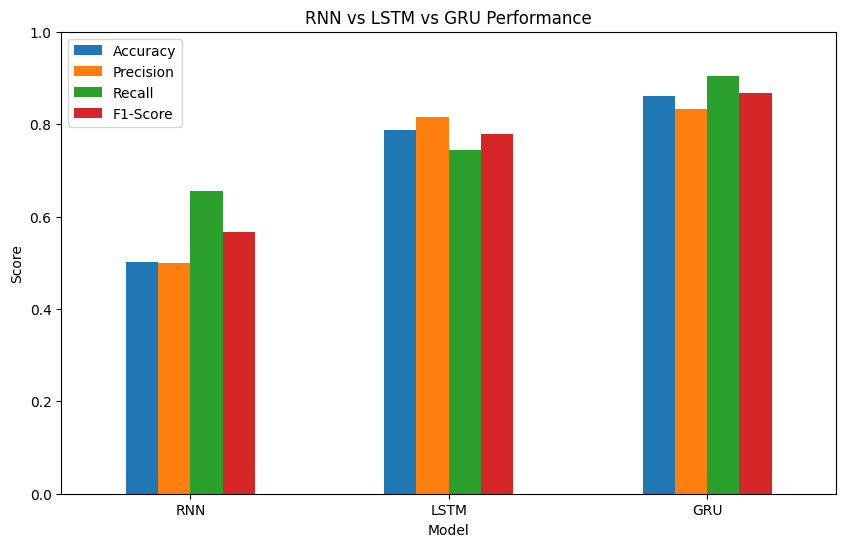

In [14]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("RNN vs LSTM vs GRU Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

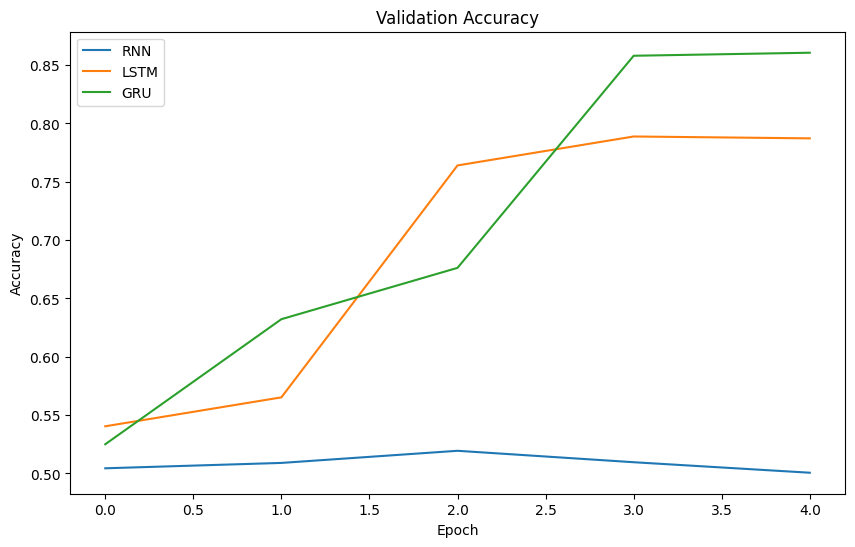

In [15]:
plt.figure(figsize=(10, 6))

plt.plot(rnn_history.history["val_accuracy"], label="RNN")
plt.plot(lstm_history.history["val_accuracy"], label="LSTM")
plt.plot(gru_history.history["val_accuracy"], label="GRU")

plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()